In [26]:
import pandas as pd
import numpy as np
print("Libraries imported successfully!")

Libraries imported successfully!


In [27]:
import pandas as pd
import numpy as np

df = pd.read_csv(r"F:\Axcentra_End_to_End_Project\excent_data.csv")

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

df.head(10)

Dataset loaded successfully!
Rows and columns: (700, 16)


,Segment,Country,Product,Discount Band,Units Sold,Manufacturing Price,Sale Price,Gross Sales,Discounts,Sales,COGS,Profit,Date,Month Number,Month Name,Year
0,Government,Germany,Carretera,NaN,1513.0,3,350,529550.0,0.0,529550.0,393380.0,136170.0,1-Dec-14,12,December,2014
1,Government,Germany,Paseo,NaN,1006.0,10,350,352100.0,0.0,352100.0,261560.0,90540.0,1-Jun-14,6,June,2014
2,Government,Canada,Paseo,NaN,1725.0,10,350,603750.0,0.0,603750.0,448500.0,155250.0,1-Nov-13,11,November,2013
3,Government,Germany,Paseo,NaN,1513.0,10,350,529550.0,0.0,529550.0,393380.0,136170.0,1-Dec-14,12,December,2014
4,Government,Germany,Velo,NaN,1006.0,120,350,352100.0,0.0,352100.0,261560.0,90540.0,1-Jun-14,6,June,2014
5,Government,France,VTT,NaN,1527.0,250,350,534450.0,0.0,534450.0,397020.0,137430.0,1-Sep-13,9,September,2013
6,Government,France,Amarilla,NaN,2750.0,260,350,962500.0,0.0,962500.0,715000.0,247500.0,1-Feb-14,2,February,2014
7,Government,Mexico,Carretera,Low,1210.0,3,350,423500.0,4235.0,419265.0,314600.0,104665.0,1-Mar-14,3,March,2014
8,Government,Mexico,Carretera,Low,1397.0,3,350,488950.0,4889.5,484060.5,363220.0,120840.5,1-Oct-14,10,October,2014
9,Government,France,Carretera,Low,2155.0,3,350,754250.0,7542.5,746707.5,560300.0,186407.5,1-Dec-14,12,December,2014


In [28]:
print("Dataset shape:", df.shape)

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nTotal duplicate rows:", df.duplicated().sum())

Dataset shape: (700, 16)

Missing values in each column:
Segment                 0
Country                 0
Product                 0
Discount Band          53
Units Sold              0
Manufacturing Price     0
Sale Price              0
Gross Sales             0
Discounts               0
 Sales                  0
COGS                    0
Profit                  0
Date                    0
Month Number            0
Month Name              0
Year                    0
dtype: int64

Total duplicate rows: 0


In [34]:

print("Current DataFrame columns:")
print(df.columns.tolist())

print("\nDataFrame shape:")
print(df.shape)


Current DataFrame columns:
['Segment', 'Country', 'Product', 'Discount Band', 'Units Sold', 'Manufacturing Price', 'Sale Price', 'Gross Sales', 'Discounts', ' Sales', 'COGS', 'Profit', 'Date', 'Month Number', 'Month Name', 'Year']

DataFrame shape:
(700, 16)


In [36]:

# Remove leading/trailing spaces from column names
df.columns = df.columns.str.strip()

# Check whether Sales exists now
print([repr(col) for col in df.columns])


["'Segment'", "'Country'", "'Product'", "'Discount Band'", "'Units Sold'", "'Manufacturing Price'", "'Sale Price'", "'Gross Sales'", "'Discounts'", "'Sales'", "'COGS'", "'Profit'", "'Date'", "'Month Number'", "'Month Name'", "'Year'"]


In [37]:
df.loc[
    df["Discount Band"].isna(),
    ["Discount Band", "Discounts", "Sales", "Profit"]
].head(15)


,Discount Band,Discounts,Sales,Profit
0,NaN,0.0,529550.0,136170.0
1,NaN,0.0,352100.0,90540.0
2,NaN,0.0,603750.0,155250.0
3,NaN,0.0,529550.0,136170.0
4,NaN,0.0,352100.0,90540.0
5,NaN,0.0,534450.0,137430.0
6,NaN,0.0,962500.0,247500.0
100,NaN,0.0,32370.0,16185.0
101,NaN,0.0,26420.0,13210.0
102,NaN,0.0,37980.0,18990.0


In [38]:
print("Discount Band values:")
print(df["Discount Band"].value_counts(dropna=False))

print("\nDiscounts summary:")
print(df["Discounts"].describe())

print("\nSample rows:")
df[["Discount Band", "Gross Sales", "Discounts", "Sales", "Profit"]].head(10)

Discount Band values:
Discount Band
High      245
Medium    242
Low       160
NaN        53
Name: count, dtype: int64

Discounts summary:
count       700.000000
mean      13150.354629
std       22962.928775
min           0.000000
25%         800.320000
50%        2585.250000
75%       15956.343750
max      149677.500000
Name: Discounts, dtype: float64

Sample rows:


,Discount Band,Gross Sales,Discounts,Sales,Profit
0,NaN,529550.0,0.0,529550.0,136170.0
1,NaN,352100.0,0.0,352100.0,90540.0
2,NaN,603750.0,0.0,603750.0,155250.0
3,NaN,529550.0,0.0,529550.0,136170.0
4,NaN,352100.0,0.0,352100.0,90540.0
5,NaN,534450.0,0.0,534450.0,137430.0
6,NaN,962500.0,0.0,962500.0,247500.0
7,Low,423500.0,4235.0,419265.0,104665.0
8,Low,488950.0,4889.5,484060.5,120840.5
9,Low,754250.0,7542.5,746707.5,186407.5


- High: 245 rows
- Medium: 242 rows
- Low: 160 rows
- Missing: 53 rows
- Missing rows mein Discounts = 0 hai aur Sales = Gross Sales hai.
Isse lagta hai ki in 53 rows mein discount apply nahi hua. Lekin Discount Band ka missing hona aur None hona technically alag hai. Isliye original category ko preserve karte hue hum missing values ko None label kar sakte hain, agar business interpretation yahi hai ki zero discount means no discount.

In [39]:
##Missing Discount Band handle karo
df["Discount Band"] = df["Discount Band"].fillna("None")

print(df["Discount Band"].value_counts(dropna=False))
print("\nRemaining missing values:", df["Discount Band"].isna().sum())
##Tumne Discount Band ki 53 missing values ko None se replace kar diya hai. Ab is column mein missing values 0 hain.

Discount Band
High      245
Medium    242
Low       160
None       53
Name: count, dtype: int64

Remaining missing values: 0


In [40]:
##Date column ka datatype check karo
print("Date datatype before conversion:", df["Date"].dtype)

df["Date"] = pd.to_datetime(
    df["Date"],
    format="%d-%b-%y",
    errors="coerce"
)

print("Date datatype after conversion:", df["Date"].dtype)
print("Invalid dates:", df["Date"].isna().sum())

df[["Date", "Month Name", "Year"]].head(10)

Date datatype before conversion: object
Date datatype after conversion: datetime64[ns]
Invalid dates: 0


,Date,Month Name,Year
0,2014-12-01,December,2014
1,2014-06-01,June,2014
2,2013-11-01,November,2013
3,2014-12-01,December,2014
4,2014-06-01,June,2014
5,2013-09-01,September,2013
6,2014-02-01,February,2014
7,2014-03-01,March,2014
8,2014-10-01,October,2014
9,2014-12-01,December,2014


In [41]:
##Date conversion verify karo
print("Date datatype:", df["Date"].dtype)
print("Invalid dates:", df["Date"].isna().sum())

Date datatype: datetime64[ns]
Invalid dates: 0


In [42]:
##Numeric columns validate karo
numeric_cols = [
    "Units Sold",
    "Manufacturing Price",
    "Sale Price",
    "Gross Sales",
    "Discounts",
    "Sales",
    "COGS",
    "Profit",
    "Month Number",
    "Year"
]

print(df[numeric_cols].dtypes)
print("\nMissing values in numeric columns:")
print(df[numeric_cols].isna().sum())

Units Sold             float64
Manufacturing Price      int64
Sale Price               int64
Gross Sales            float64
Discounts              float64
Sales                  float64
COGS                   float64
Profit                 float64
Month Number             int64
Year                     int64
dtype: object

Missing values in numeric columns:
Units Sold             0
Manufacturing Price    0
Sale Price             0
Gross Sales            0
Discounts              0
Sales                  0
COGS                   0
Profit                 0
Month Number           0
Year                   0
dtype: int64


In [43]:

import os

project_path = r"F:\Axcentra_End_to_End_Project"
os.makedirs(os.path.join(project_path, "data"), exist_ok=True)

print("Folder ready:", os.path.join(project_path, "data"))


Folder ready: F:\Axcentra_End_to_End_Project\data


In [ ]:
##save cleaned file
df.to_csv(
    r"F:\Axcentra_End_to_End_Project\data\cleaned_data.csv",
    index=False
)

print("CSV saved successfully!")


In [45]:

# Overall Sales and Profit Summary

print("Total Sales:", round(df["Sales"].sum(), 2))
print("Total Profit:", round(df["Profit"].sum(), 2))
print("Total Units Sold:", df["Units Sold"].sum())
print("Average Sales:", round(df["Sales"].mean(), 2))
print("Average Profit:", round(df["Profit"].mean(), 2))

# Profit Margin
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()

profit_margin = (total_profit / total_sales) * 100

print("Overall Profit Margin:", round(profit_margin, 2), "%")


Total Sales: 118726350.26
Total Profit: 16893702.26
Total Units Sold: 1125806.0
Average Sales: 169609.07
Average Profit: 24133.86
Overall Profit Margin: 14.23 %


In [46]:
# Country-wise Sales and Profit Analysis
country_analysis = df.groupby("Country").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Units_Sold=("Units Sold", "sum")
).reset_index()

country_analysis = country_analysis.sort_values(
    by="Total_Sales", ascending=False
)

display(country_analysis.round(2))


,Country,Total_Sales,Total_Profit,Total_Units_Sold
4,United States of America,25029830.16,2995540.66,232627.5
0,Canada,24887654.88,3529228.88,247428.5
1,France,24354172.28,3781020.78,240931.0
2,Germany,23505340.82,3680388.82,201494.0
3,Mexico,20949352.11,2907523.11,203325.0


In [47]:

# Product-wise Sales and Profit Analysis

product_analysis = df.groupby("Product").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Units_Sold=("Units Sold", "sum")
).reset_index()

product_analysis = product_analysis.sort_values(
    by="Total_Sales", ascending=False
)

display(product_analysis.round(2))


,Product,Total_Sales,Total_Profit,Total_Units_Sold
3,Paseo,33011143.95,4797437.95,338239.5
4,VTT,20511921.02,3034608.02,168783.0
5,Velo,18250059.46,2305992.46,162424.5
0,Amarilla,17747116.06,2814104.06,155315.0
2,Montana,15390801.88,2114754.88,154198.0
1,Carretera,13815307.88,1826804.88,146846.0


In [50]:

# Segment-wise Sales and Profit Analysis

segment_analysis = df.groupby("Segment").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Units_Sold=("Units Sold", "sum")
).reset_index()

segment_analysis = segment_analysis.sort_values(
    by="Total_Sales", ascending=False
)

display(segment_analysis.round(2))


,Segment,Total_Sales,Total_Profit,Total_Units_Sold
2,Government,52504260.67,11388173.17,470673.5
4,Small Business,42427918.50,4143168.50,153139.0
1,Enterprise,19611694.38,-614545.62,168552.0
3,Midmarket,2381883.08,660103.07,172178.0
0,Channel Partners,1800593.64,1316803.14,161263.5


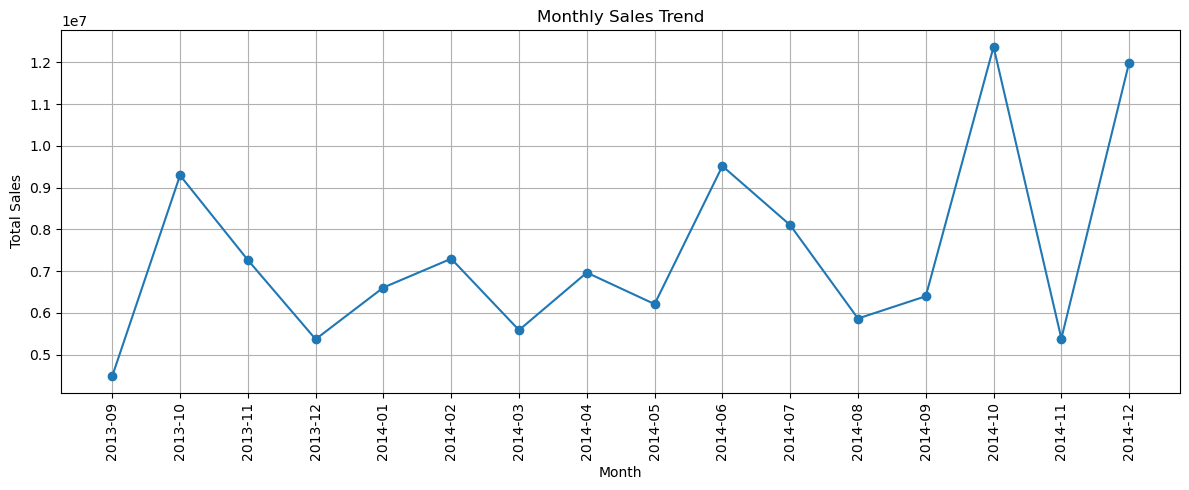

In [51]:

import matplotlib.pyplot as plt
import pandas as pd

# Convert Date column into datetime format
df["Date"] = pd.to_datetime(df["Date"])

# Group sales by month
monthly_sales = df.groupby(
    df["Date"].dt.to_period("M")
)["Sales"].sum().reset_index()

monthly_sales["Date"] = monthly_sales["Date"].astype(str)

# Plot monthly sales trend
plt.figure(figsize=(12, 5))
plt.plot(
    monthly_sales["Date"],
    monthly_sales["Sales"],
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=90)
plt.grid(True)
plt.tight_layout()
plt.show()


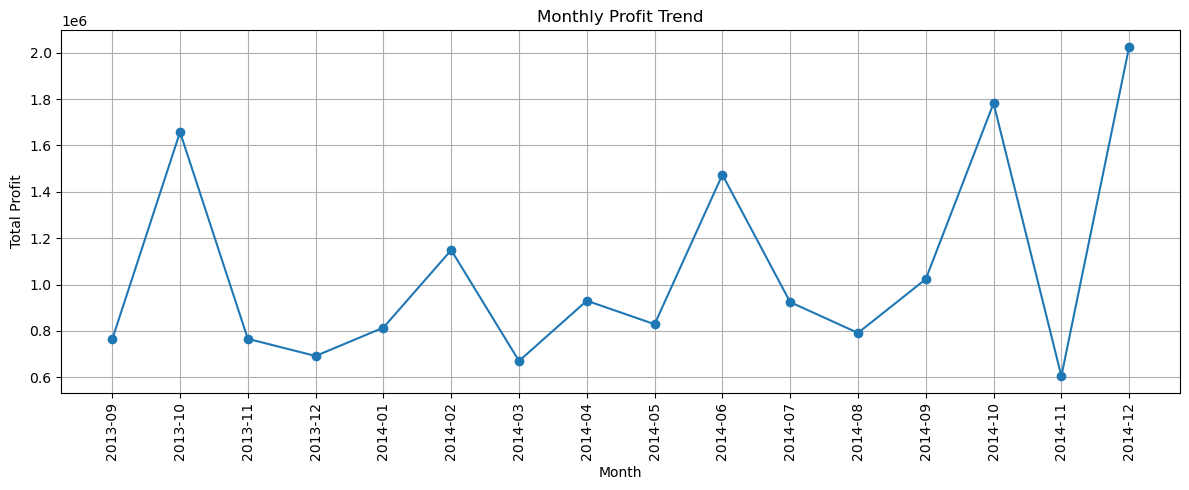

In [52]:

# Monthly Profit Trend

monthly_profit = df.groupby(
    df["Date"].dt.to_period("M")
)["Profit"].sum().reset_index()

monthly_profit["Date"] = monthly_profit["Date"].astype(str)

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_profit["Date"],
    monthly_profit["Profit"],
    marker="o"
)

plt.title("Monthly Profit Trend")
plt.xlabel("Month")
plt.ylabel("Total Profit")
plt.xticks(rotation=90)
plt.grid(True)
plt.tight_layout()
plt.show()


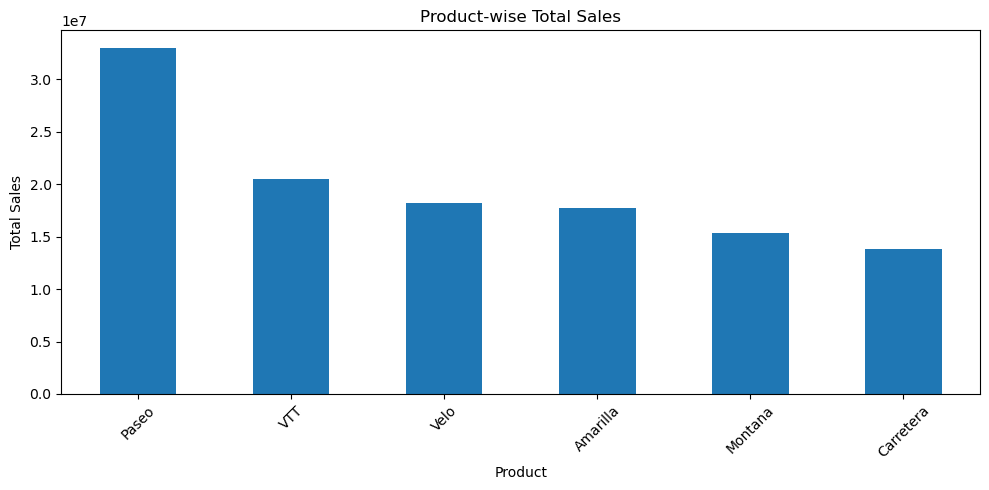

In [53]:

# Product-wise Sales Visualization

product_sales = df.groupby("Product")["Sales"].sum().sort_values(
    ascending=False
)

plt.figure(figsize=(10, 5))

product_sales.plot(kind="bar")

plt.title("Product-wise Total Sales")
plt.xlabel("Product")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


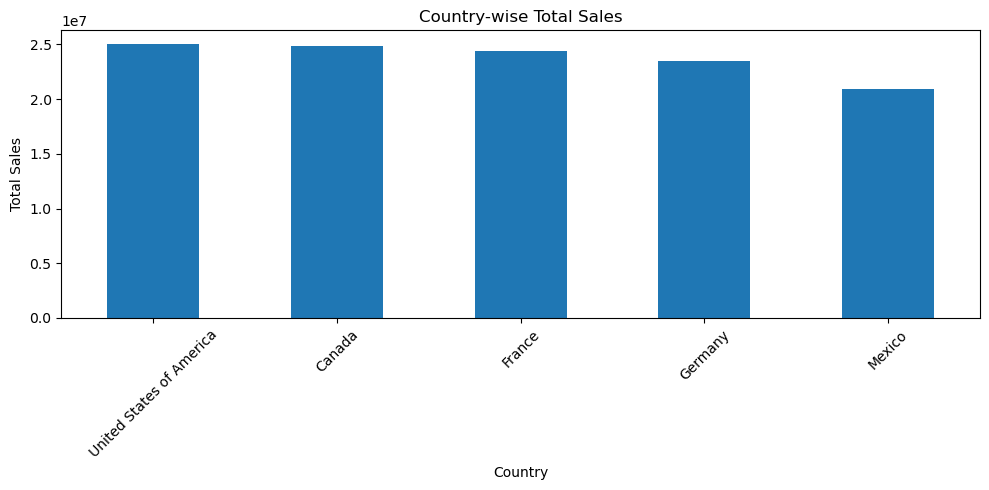

In [54]:

# Country-wise Sales Visualization

country_sales = df.groupby("Country")["Sales"].sum().sort_values(
    ascending=False
)

plt.figure(figsize=(10, 5))

country_sales.plot(kind="bar")

plt.title("Country-wise Total Sales")
plt.xlabel("Country")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


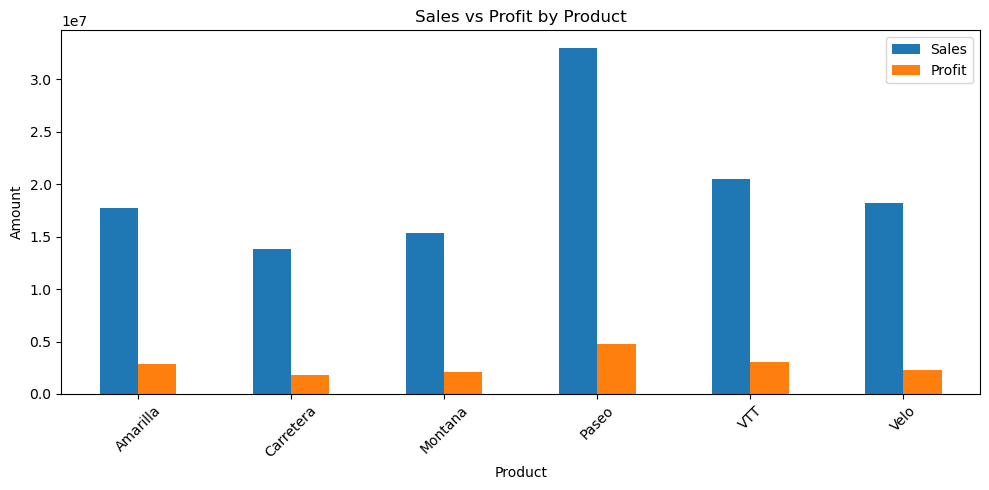

In [55]:

# Sales vs Profit by Product

product_performance = df.groupby("Product")[["Sales", "Profit"]].sum()

product_performance.plot(kind="bar", figsize=(10, 5))

plt.title("Sales vs Profit by Product")
plt.xlabel("Product")
plt.ylabel("Amount")
plt.xticks(rotation=45)
plt.legend(["Sales", "Profit"])
plt.tight_layout()
plt.show()
